# Исследовательский анализ обучающей выборки

Цель — изучить связь доступных клиентских признаков с неплатежом
в следующем месяце и подготовить простое базовое правило.

Используется только train.csv — 24 000 наблюдений.

Тестовая выборка не используется для исследования, выбора признаков
и настройки правил.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

TARGET = "default payment next month"

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
train = pd.read_csv("train.csv")

train.shape

(24000, 25)

In [ ]:
train_summary = pd.Series({
    "Клиентов": len(train),
    "Событий неплатежа": train[TARGET].sum(),
    "Доля событий, %": train[TARGET].mean() * 100,
    "Уникальных ID": train["ID"].nunique()
})

train_summary

,0
Клиентов,24000.000000
Событий неплатежа,5309.000000
"Доля событий, %",22.120833
Уникальных ID,24000.000000


In [ ]:
pay0_summary = (
    train
    .groupby("PAY_0")
    .agg(
        clients=("ID", "size"),
        events=(TARGET, "sum"),
        event_rate=(TARGET, "mean")
    )
    .reset_index()
    .sort_values("PAY_0")
)

pay0_summary["client_share_pct"] = (
    pay0_summary["clients"] / len(train) * 100
)

pay0_summary["event_rate_pct"] = (
    pay0_summary["event_rate"] * 100
)

pay0_summary[
    [
        "PAY_0",
        "clients",
        "client_share_pct",
        "events",
        "event_rate_pct"
    ]
].round(2)

,PAY_0,clients,client_share_pct,events,event_rate_pct
0,-2,2198,9.16,279,12.69
1,-1,4527,18.86,753,16.63
2,0,11781,49.09,1508,12.80
3,1,3000,12.50,1031,34.37
4,2,2138,8.91,1483,69.36
5,3,245,1.02,188,76.73
6,4,58,0.24,38,65.52
7,5,18,0.08,8,44.44
8,6,10,0.04,6,60.00
9,7,9,0.04,7,77.78


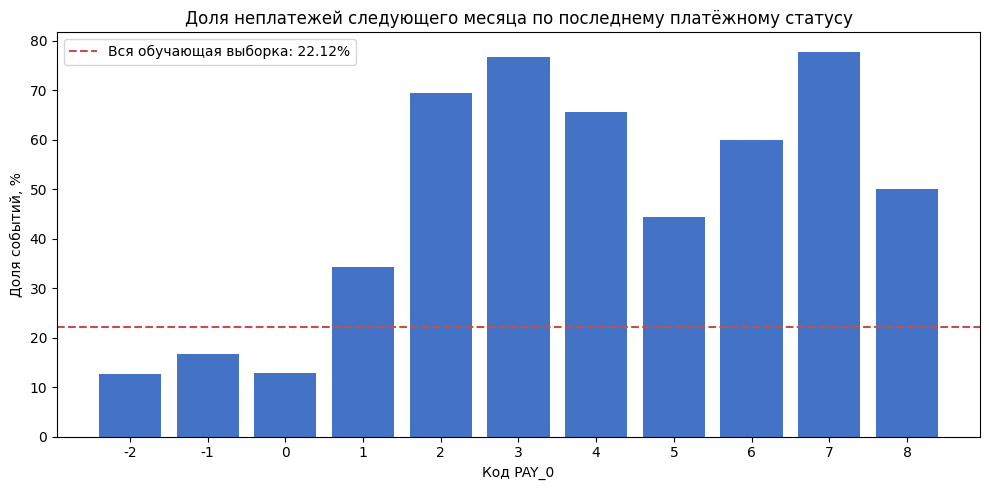

In [ ]:
base_rate_pct = train[TARGET].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    pay0_summary["PAY_0"].astype(str),
    pay0_summary["event_rate_pct"],
    color="#4472C4"
)

ax.axhline(
    base_rate_pct,
    color="#C0504D",
    linestyle="--",
    label=f"Вся обучающая выборка: {base_rate_pct:.2f}%"
)

ax.set_title(
    "Доля неплатежей следующего месяца по последнему платёжному статусу"
)
ax.set_xlabel("Код PAY_0")
ax.set_ylabel("Доля событий, %")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
def evaluate_rule(data, selected, rule_name):
    y = data[TARGET]
    selected = selected.astype(bool)

    tp = int(((y == 1) & selected).sum())
    fp = int(((y == 0) & selected).sum())
    fn = int(((y == 1) & ~selected).sum())
    tn = int(((y == 0) & ~selected).sum())

    selected_count = tp + fp
    event_count = tp + fn
    base_rate = y.mean()

    precision = tp / selected_count if selected_count else float("nan")
    recall = tp / event_count if event_count else float("nan")

    return {
        "Правило": rule_name,
        "На проверку, клиентов": selected_count,
        "Нагрузка, %": selected_count / len(data) * 100,
        "Событий в отборе": tp,
        "Без события в отборе": fp,
        "Пропущено событий": fn,
        "Без события вне отбора": tn,
        "Precision, %": precision * 100,
        "Recall, %": recall * 100,
        "Lift": precision / base_rate if base_rate else float("nan")
    }

In [ ]:
baseline_results = pd.DataFrame([
    evaluate_rule(
        train,
        train["PAY_0"] >= 2,
        "PAY_0 >= 2"
    ),
    evaluate_rule(
        train,
        train["PAY_0"] >= 1,
        "PAY_0 >= 1"
    )
])

baseline_results.round(2)

,Правило,"На проверку, клиентов","Нагрузка, %",Событий в отборе,Без события в отборе,Пропущено событий,Без события вне отбора,"Precision, %","Recall, %",Lift
0,PAY_0 >= 2,2494,10.39,1738,756,3571,17935,69.69,32.74,3.15
1,PAY_0 >= 1,5494,22.89,2769,2725,2540,15966,50.40,52.16,2.28


## Предварительные выводы по PAY_0

На обучающей выборке частота неплатежа различается между группами
последнего платёжного статуса.

В группе PAY_0 = 0 частота события составляет 12,80%,
при PAY_0 = 1 — 34,37%, при PAY_0 = 2 — 69,36%.

Редкие категории не используются для самостоятельного ранжирования
по наблюдаемой частоте события из-за малого числа клиентов.

Для дальнейшего сравнения зафиксированы два прозрачных правила:
PAY_0 >= 2 и PAY_0 >= 1.

Правила оцениваются по нагрузке, precision, recall и количеству
пропущенных событий. Полученные оценки относятся к обучающей выборке
и пока не подтверждают качество на новых данных.

In [5]:
payment_status_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

payment_status_results = []

for column in payment_status_columns:
    summary = (
        train
        .groupby(column)
        .agg(
            clients=("ID", "size"),
            events=(TARGET, "sum"),
            event_rate=(TARGET, "mean")
        )
        .reset_index()
    )

    summary.insert(0, "payment_status_column", column)
    summary["client_share_pct"] = summary["clients"] / len(train) * 100
    summary["event_rate_pct"] = summary["event_rate"] * 100

    payment_status_results.append(summary)

payment_status_summary = pd.concat(
    payment_status_results,
    ignore_index=True
)

payment_status_summary.round(2)

,payment_status_column,PAY_0,clients,events,event_rate,client_share_pct,event_rate_pct,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
0,PAY_0,-2.0,2198,279,0.13,9.16,12.69,NaN,NaN,NaN,NaN,NaN
1,PAY_0,-1.0,4527,753,0.17,18.86,16.63,NaN,NaN,NaN,NaN,NaN
2,PAY_0,0.0,11781,1508,0.13,49.09,12.80,NaN,NaN,NaN,NaN,NaN
3,PAY_0,1.0,3000,1031,0.34,12.50,34.37,NaN,NaN,NaN,NaN,NaN
4,PAY_0,2.0,2138,1483,0.69,8.91,69.36,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
59,PAY_6,NaN,42,29,0.69,0.18,69.05,NaN,NaN,NaN,NaN,4.0
60,PAY_6,NaN,8,5,0.62,0.03,62.50,NaN,NaN,NaN,NaN,5.0
61,PAY_6,NaN,11,8,0.73,0.05,72.73,NaN,NaN,NaN,NaN,6.0
62,PAY_6,NaN,33,27,0.82,0.14,81.82,NaN,NaN,NaN,NaN,7.0


In [6]:
payment_status_summary[
    payment_status_summary["clients"] >= 100
].round(2)

,payment_status_column,PAY_0,clients,events,event_rate,client_share_pct,event_rate_pct,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
0,PAY_0,-2.0,2198,279,0.13,9.16,12.69,NaN,NaN,NaN,NaN,NaN
1,PAY_0,-1.0,4527,753,0.17,18.86,16.63,NaN,NaN,NaN,NaN,NaN
2,PAY_0,0.0,11781,1508,0.13,49.09,12.80,NaN,NaN,NaN,NaN,NaN
3,PAY_0,1.0,3000,1031,0.34,12.50,34.37,NaN,NaN,NaN,NaN,NaN
4,PAY_0,2.0,2138,1483,0.69,8.91,69.36,NaN,NaN,NaN,NaN,NaN
5,PAY_0,3.0,245,188,0.77,1.02,76.73,NaN,NaN,NaN,NaN,NaN
11,PAY_2,NaN,3030,544,0.18,12.62,17.95,-2.0,NaN,NaN,NaN,NaN
12,PAY_2,NaN,4845,774,0.16,20.19,15.98,-1.0,NaN,NaN,NaN,NaN
13,PAY_2,NaN,12573,2006,0.16,52.39,15.95,0.0,NaN,NaN,NaN,NaN
15,PAY_2,NaN,3145,1749,0.56,13.10,55.61,2.0,NaN,NaN,NaN,NaN


In [7]:
category_columns = ["EDUCATION", "MARRIAGE"]

category_results = []

for column in category_columns:
    summary = (
        train
        .groupby(column)
        .agg(
            clients=("ID", "size"),
            events=(TARGET, "sum"),
            event_rate=(TARGET, "mean")
        )
        .reset_index()
    )

    summary.insert(0, "category_column", column)
    summary["client_share_pct"] = summary["clients"] / len(train) * 100
    summary["event_rate_pct"] = summary["event_rate"] * 100

    category_results.append(summary)

category_summary = pd.concat(
    category_results,
    ignore_index=True
)

category_summary.round(2)

,category_column,EDUCATION,clients,events,event_rate,client_share_pct,event_rate_pct,MARRIAGE
0,EDUCATION,0.0,12,0,0.00,0.05,0.00,NaN
1,EDUCATION,1.0,8455,1631,0.19,35.23,19.29,NaN
2,EDUCATION,2.0,11256,2674,0.24,46.90,23.76,NaN
3,EDUCATION,3.0,3903,976,0.25,16.26,25.01,NaN
4,EDUCATION,4.0,97,6,0.06,0.40,6.19,NaN
5,EDUCATION,5.0,235,15,0.06,0.98,6.38,NaN
6,EDUCATION,6.0,42,7,0.17,0.18,16.67,NaN
7,MARRIAGE,NaN,47,5,0.11,0.20,10.64,0.0
8,MARRIAGE,NaN,10892,2538,0.23,45.38,23.30,1.0
9,MARRIAGE,NaN,12806,2694,0.21,53.36,21.04,2.0


In [8]:
numeric_columns = [
    "LIMIT_BAL",
    "AGE",
    *[f"BILL_AMT{i}" for i in range(1, 7)],
    *[f"PAY_AMT{i}" for i in range(1, 7)]
]

numeric_correlations = train[numeric_columns].corr()

numeric_correlations.round(2)

,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
LIMIT_BAL,1.00,0.15,0.28,0.28,0.28,0.29,0.29,0.29,0.19,0.19,0.21,0.20,0.22,0.22
AGE,0.15,1.00,0.06,0.06,0.06,0.05,0.05,0.05,0.03,0.03,0.03,0.02,0.03,0.02
BILL_AMT1,0.28,0.06,1.00,0.95,0.90,0.86,0.83,0.80,0.14,0.11,0.16,0.16,0.17,0.18
BILL_AMT2,0.28,0.06,0.95,1.00,0.94,0.89,0.86,0.83,0.27,0.10,0.16,0.15,0.16,0.17
BILL_AMT3,0.28,0.06,0.90,0.94,1.00,0.93,0.89,0.86,0.24,0.29,0.13,0.14,0.16,0.18
BILL_AMT4,0.29,0.05,0.86,0.89,0.93,1.00,0.94,0.90,0.23,0.23,0.30,0.14,0.16,0.18
BILL_AMT5,0.29,0.05,0.83,0.86,0.89,0.94,1.00,0.95,0.21,0.20,0.26,0.29,0.14,0.16
BILL_AMT6,0.29,0.05,0.80,0.83,0.86,0.90,0.95,1.00,0.19,0.18,0.24,0.25,0.31,0.11
PAY_AMT1,0.19,0.03,0.14,0.27,0.24,0.23,0.21,0.19,1.00,0.31,0.26,0.22,0.15,0.20
PAY_AMT2,0.19,0.03,0.11,0.10,0.29,0.23,0.20,0.18,0.31,1.00,0.27,0.22,0.15,0.19


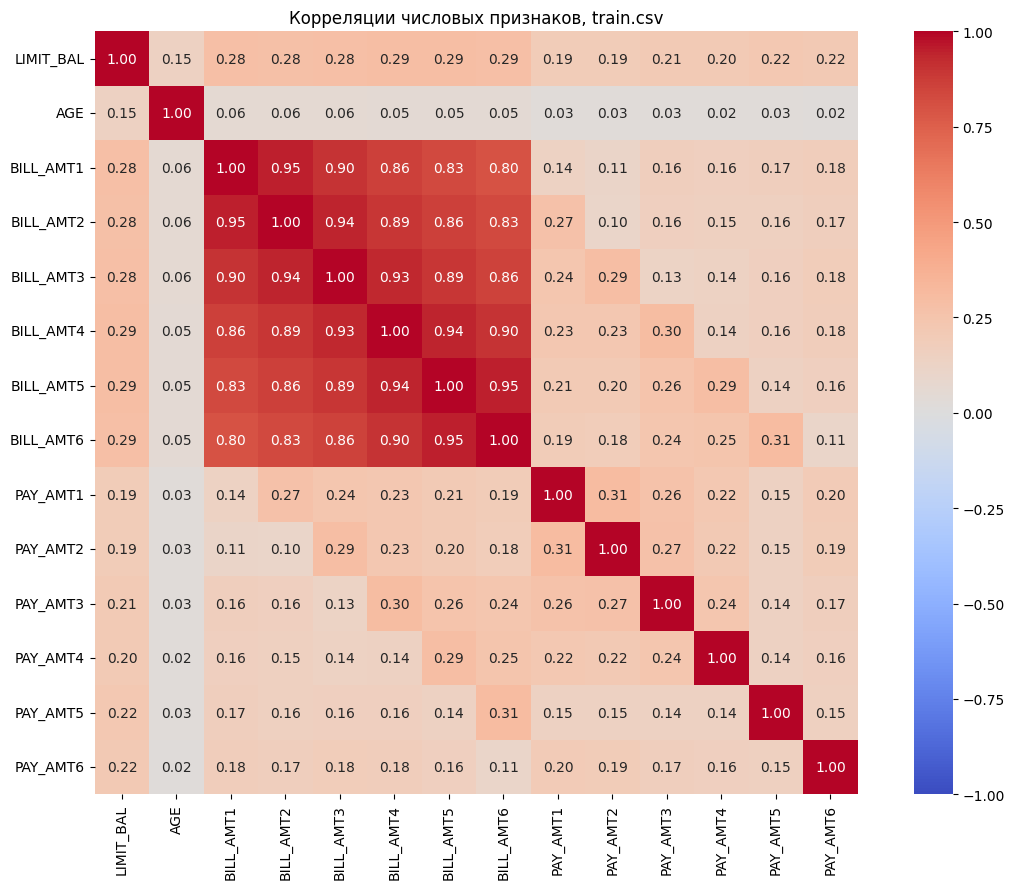

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Корреляции числовых признаков, train.csv")
plt.tight_layout()
plt.show()